In [4]:
# ── Colab Setup: install dependencies & download datasets from Kaggle ────────
# Skip this cell if running locally with data already present.

import subprocess, sys, os
from pathlib import Path

# Install required packages (no-op if already installed)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'kagglehub', 'librosa', 'scikit-learn', 'torch', 'seaborn'])

import kagglehub

# Download datasets via kagglehub
shords_path = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
audio_files_path = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

print(f"shords_dataset downloaded to: {shords_path}")
print(f"Audio_Files downloaded to:    {audio_files_path}")

# Create expected directory structure: data/shords_dataset/{major,minor} and data/Audio_Files/{Major,Minor}
data_dir = Path('data')

# Symlink or copy shords_dataset
shords_dest = data_dir / 'shords_dataset'
audio_dest  = data_dir / 'Audio_Files'

if not shords_dest.exists():
    shords_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(shords_path, str(shords_dest))
    print(f"Linked {shords_path} → {shords_dest}")

if not audio_dest.exists():
    audio_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(audio_files_path, str(audio_dest))
    print(f"Linked {audio_files_path} → {audio_dest}")

# Verify
for sub in ['shords_dataset/major', 'shords_dataset/minor', 'Audio_Files/Major', 'Audio_Files/Minor']:
    p = data_dir / sub
    n = len(list(p.glob('*.wav'))) if p.exists() else 0
    print(f"  {sub}: {n} files")

shords_dataset downloaded to: /root/.cache/kagglehub/datasets/mehanat96/major-vs-minor-guitar-chords/versions/1
Audio_Files downloaded to:    /root/.cache/kagglehub/datasets/deepcontractor/musical-instrument-chord-classification/versions/2
  shords_dataset/major: 0 files
  shords_dataset/minor: 0 files
  Audio_Files/Major: 0 files
  Audio_Files/Minor: 0 files


# Windowing Experiment — Does splitting 2 s audio into smaller windows improve classification?

**Hypothesis:** Extracting features (chroma + MFCC) from the full 2-second clip averages out temporal detail. Splitting into smaller, overlapping sub-windows and aggregating per-window features (mean + std) may expose more structure and improve model accuracy.

**Setup:**
- **Baseline:** single 2 s window → 25 features (12 chroma + 13 MFCC means)
- **Windowed variants:** split into sub-windows of 1.0 s, 0.5 s, 0.25 s with 50 % overlap, extract chroma + MFCC per window, then take mean **and** std across windows → richer feature vectors
- All variants are evaluated with the same train/test split and models (RF, SVM, KNN, LR)
- We use both datasets (Audio_Files + shords_dataset) combined

In [7]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from src.features import load_audio, normalize_duration, extract_chroma, extract_mfcc, extract_all_features
from src.dataset import split_dataset

import warnings
warnings.filterwarnings('ignore')

ModuleNotFoundError: No module named 'src'

## 1. Load both datasets (raw audio)

In [ ]:
SR = 22050
TARGET_DURATION = 2.0

AUDIO_DIR = Path('../data/Audio_Files')
SHORDS_DIR = Path('../data/shords_dataset')

def load_raw_audio(data_dir, sr=SR, target_duration=TARGET_DURATION):
    """Load raw audio waveforms and labels from a directory (major/minor subdirs)."""
    data_dir = Path(data_dir)
    waveforms = []
    labels = []
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        for audio_file in sorted(label_dir.iterdir()):
            if audio_file.suffix not in ['.wav', '.mp3', '.flac', '.ogg']:
                continue
            y, _ = load_audio(str(audio_file), sr=sr, target_duration=target_duration)
            waveforms.append(y)
            labels.append(label)
    return waveforms, labels

# Load both datasets
waveforms_audio, labels_audio = load_raw_audio(AUDIO_DIR)
waveforms_shords, labels_shords = load_raw_audio(SHORDS_DIR)

waveforms = waveforms_audio + waveforms_shords
labels = np.array(labels_audio + labels_shords)

print(f'Audio_Files:    {len(waveforms_audio)} samples')
print(f'shords_dataset: {len(waveforms_shords)} samples')
print(f'Combined:       {len(waveforms)} samples')
print(f'Class counts:   {dict(zip(*np.unique(labels, return_counts=True)))}')

Audio_Files:    859 samples
shords_dataset: 502 samples
Combined:       1361 samples
Class counts:   {np.str_('Major'): np.int64(752), np.str_('Minor'): np.int64(609)}


## 2. Define windowed feature extraction

For each window strategy we:
1. Split the 2 s audio into overlapping sub-windows
2. Extract chroma (12) + MFCC (13) per sub-window → 25 features per window
3. Aggregate across windows using **mean** and **std** → feature vector of length $25 \times 2 = 50$

The baseline uses a single full-length window with only the mean → 25 features.

In [3]:
def extract_windowed_features(y, sr, window_sec, overlap=0.5):
    """Split y into overlapping windows and extract chroma+MFCC per window.
    
    Returns a 1-D feature vector: [mean_of_all_windows | std_of_all_windows].
    """
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    
    # Collect per-window feature vectors
    window_features = []
    start = 0
    while start + window_samples <= len(y):
        segment = y[start:start + window_samples]
        chroma = extract_chroma(segment, sr)    # 12
        mfcc = extract_mfcc(segment, sr)        # 13
        window_features.append(np.concatenate([chroma, mfcc]))
        start += hop_samples
    
    # Handle edge case: if audio shorter than one window
    if len(window_features) == 0:
        chroma = extract_chroma(y, sr)
        mfcc = extract_mfcc(y, sr)
        window_features.append(np.concatenate([chroma, mfcc]))
    
    window_features = np.array(window_features)  # shape: (n_windows, 25)
    
    # Aggregate: mean + std across windows
    feat_mean = np.mean(window_features, axis=0)
    feat_std = np.std(window_features, axis=0)
    
    return np.concatenate([feat_mean, feat_std])


def build_feature_matrix(waveforms, sr, window_sec, overlap=0.5):
    """Build feature matrix for all samples using a given window size."""
    features = []
    for y in waveforms:
        feat = extract_windowed_features(y, sr, window_sec, overlap)
        features.append(feat)
    return np.array(features)


# Also build baseline (full 2 s, mean only — original approach)
def build_baseline_features(waveforms, sr):
    """Original approach: single window, mean chroma + MFCC = 25 features."""
    features = []
    for y in waveforms:
        feat = extract_all_features(y, sr)
        features.append(feat)
    return np.array(features)


# Window configs to test
WINDOW_CONFIGS = {
    'Baseline (2.0 s, mean only)': None,  # special-cased
    '1.0 s windows':  1.0,
    '0.5 s windows':  0.5,
    '0.25 s windows': 0.25,
}

print('Window configurations defined.')
for name, w in WINDOW_CONFIGS.items():
    if w is None:
        print(f'  {name}: 1 window  → 25 features')
    else:
        n_windows = int((TARGET_DURATION - w) / (w * 0.5)) + 1
        print(f'  {name}: ~{n_windows} windows → {25 * 2} features')

Window configurations defined.
  Baseline (2.0 s, mean only): 1 window  → 25 features
  1.0 s windows: ~3 windows → 50 features
  0.5 s windows: ~7 windows → 50 features
  0.25 s windows: ~15 windows → 50 features


## 3. Build feature matrices for each window strategy

In [4]:
feature_sets = {}

for name, window_sec in WINDOW_CONFIGS.items():
    if window_sec is None:
        X = build_baseline_features(waveforms, SR)
    else:
        X = build_feature_matrix(waveforms, SR, window_sec, overlap=0.5)
    feature_sets[name] = X
    print(f'{name}: feature matrix shape = {X.shape}')

# Encode labels
le = LabelEncoder()
y = le.fit_transform(labels)
print(f'\nLabels encoded: {le.classes_} → {list(range(len(le.classes_)))}')

Baseline (2.0 s, mean only): feature matrix shape = (1361, 25)
1.0 s windows: feature matrix shape = (1361, 50)
0.5 s windows: feature matrix shape = (1361, 50)
0.25 s windows: feature matrix shape = (1361, 50)

Labels encoded: ['Major' 'Minor'] → [0, 1]


## 4. Cross-validated comparison across models and window strategies

We evaluate each (model × window) combination using **5-fold stratified cross-validation** with `StandardScaler` applied inside each fold.

In [5]:
from sklearn.pipeline import make_pipeline

MODELS = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM (RBF)':     SVC(kernel='rbf', random_state=42),
    'KNN (k=5)':     KNeighborsClassifier(n_neighbors=5),
    'Logistic Reg.': LogisticRegression(max_iter=1000, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for window_name, X in feature_sets.items():
    for model_name, model in MODELS.items():
        pipe = make_pipeline(StandardScaler(), model)
        scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
        results.append({
            'Window Strategy': window_name,
            'Model': model_name,
            'Mean Accuracy': scores.mean(),
            'Std': scores.std(),
            'Folds': scores.tolist(),
        })
        print(f'{window_name:32s} | {model_name:16s} | acc = {scores.mean():.4f} ± {scores.std():.4f}')

results_df = pd.DataFrame(results)
print('\nDone — all combinations evaluated.')

Baseline (2.0 s, mean only)      | Random Forest    | acc = 0.7825 ± 0.0228
Baseline (2.0 s, mean only)      | SVM (RBF)        | acc = 0.6929 ± 0.0164
Baseline (2.0 s, mean only)      | KNN (k=5)        | acc = 0.6473 ± 0.0143
Baseline (2.0 s, mean only)      | Logistic Reg.    | acc = 0.6121 ± 0.0211
1.0 s windows                    | Random Forest    | acc = 0.7663 ± 0.0235
1.0 s windows                    | SVM (RBF)        | acc = 0.7215 ± 0.0186
1.0 s windows                    | KNN (k=5)        | acc = 0.6789 ± 0.0172
1.0 s windows                    | Logistic Reg.    | acc = 0.6098 ± 0.0096
0.5 s windows                    | Random Forest    | acc = 0.7649 ± 0.0225
0.5 s windows                    | SVM (RBF)        | acc = 0.7024 ± 0.0090
0.5 s windows                    | KNN (k=5)        | acc = 0.6657 ± 0.0164
0.5 s windows                    | Logistic Reg.    | acc = 0.6209 ± 0.0158
0.25 s windows                   | Random Forest    | acc = 0.7678 ± 0.0106
0.25 s windo

## 5. Results table

In [6]:
# Pivot table: rows = window strategy, columns = model, values = accuracy
pivot = results_df.pivot_table(
    index='Window Strategy',
    columns='Model',
    values='Mean Accuracy',
)

# Re-order rows logically
row_order = [name for name in WINDOW_CONFIGS.keys()]
pivot = pivot.reindex(row_order)

display(pivot.style
    .format('{:.4f}')
    .background_gradient(cmap='YlGn', axis=None)
    .set_caption('Mean CV Accuracy by Window Strategy and Model')
)

Model,KNN (k=5),Logistic Reg.,Random Forest,SVM (RBF)
Window Strategy,,,,
"Baseline (2.0 s, mean only)",0.6473,0.6121,0.7825,0.6929
1.0 s windows,0.6789,0.6098,0.7663,0.7215
0.5 s windows,0.6657,0.6209,0.7649,0.7024
0.25 s windows,0.6708,0.6290,0.7678,0.7149


## 6. Visualisation — grouped bar chart

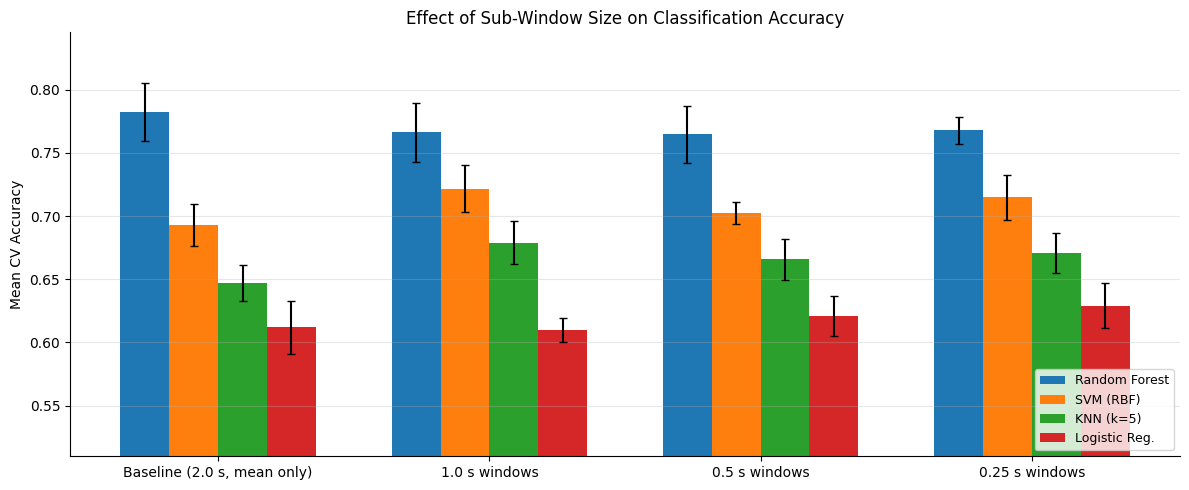

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))

window_names = list(WINDOW_CONFIGS.keys())
model_names = list(MODELS.keys())
x = np.arange(len(window_names))
width = 0.18

for i, model_name in enumerate(model_names):
    means = [results_df[(results_df['Window Strategy'] == w) & (results_df['Model'] == model_name)]['Mean Accuracy'].values[0]
             for w in window_names]
    stds  = [results_df[(results_df['Window Strategy'] == w) & (results_df['Model'] == model_name)]['Std'].values[0]
             for w in window_names]
    bars = ax.bar(x + i * width, means, width, yerr=stds, label=model_name, capsize=3)

ax.set_xticks(x + width * (len(model_names) - 1) / 2)
ax.set_xticklabels(window_names, fontsize=10)
ax.set_ylabel('Mean CV Accuracy')
ax.set_title('Effect of Sub-Window Size on Classification Accuracy')
ax.set_ylim(bottom=max(0, results_df['Mean Accuracy'].min() - 0.1))
ax.legend(loc='lower right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.show()

## 7. Per-model improvement from windowing vs baseline

In [8]:
baseline_name = 'Baseline (2.0 s, mean only)'
baseline_scores = results_df[results_df['Window Strategy'] == baseline_name].set_index('Model')['Mean Accuracy']

print('Accuracy change vs baseline (positive = windowing helps):\n')
for model_name in model_names:
    base = baseline_scores[model_name]
    print(f'  {model_name}:')
    for window_name in window_names:
        if window_name == baseline_name:
            continue
        acc = results_df[(results_df['Window Strategy'] == window_name) & 
                         (results_df['Model'] == model_name)]['Mean Accuracy'].values[0]
        delta = acc - base
        arrow = '▲' if delta > 0 else ('▼' if delta < 0 else '─')
        print(f'    {window_name:25s}  {acc:.4f}  ({arrow} {delta:+.4f})')
    print()

Accuracy change vs baseline (positive = windowing helps):

  Random Forest:
    1.0 s windows              0.7663  (▼ -0.0161)
    0.5 s windows              0.7649  (▼ -0.0176)
    0.25 s windows             0.7678  (▼ -0.0147)

  SVM (RBF):
    1.0 s windows              0.7215  (▲ +0.0287)
    0.5 s windows              0.7024  (▲ +0.0095)
    0.25 s windows             0.7149  (▲ +0.0220)

  KNN (k=5):
    1.0 s windows              0.6789  (▲ +0.0316)
    0.5 s windows              0.6657  (▲ +0.0184)
    0.25 s windows             0.6708  (▲ +0.0235)

  Logistic Reg.:
    1.0 s windows              0.6098  (▼ -0.0022)
    0.5 s windows              0.6209  (▲ +0.0088)
    0.25 s windows             0.6290  (▲ +0.0169)



## 8. Best overall configuration

In [9]:
best = results_df.loc[results_df['Mean Accuracy'].idxmax()]
print(f'Best configuration:')
print(f'  Window strategy : {best["Window Strategy"]}')
print(f'  Model           : {best["Model"]}')
print(f'  Mean CV Accuracy: {best["Mean Accuracy"]:.4f} ± {best["Std"]:.4f}')
print(f'  Per-fold scores : {[f"{s:.4f}" for s in best["Folds"]]}')

Best configuration:
  Window strategy : Baseline (2.0 s, mean only)
  Model           : Random Forest
  Mean CV Accuracy: 0.7825 ± 0.0228
  Per-fold scores : ['0.8132', '0.7831', '0.7610', '0.7537', '0.8015']


## 9. Heatmap — accuracy matrix

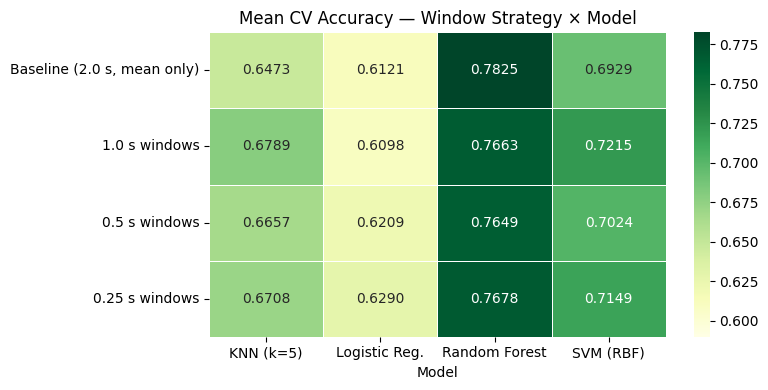

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlGn', ax=ax,
            linewidths=0.5, vmin=pivot.values.min() - 0.02)
ax.set_title('Mean CV Accuracy — Window Strategy × Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## 10. Conclusion

**Interpretation guide:**
- If windowed approaches consistently outperform the baseline → splitting into sub-windows captures useful temporal variation that mean-pooling over 2 s washes out.
- If the baseline matches or beats windowed variants → the chord signal is stationary enough that a single window suffices, and the extra features just add noise.
- Look at the ▲/▼ deltas above to judge the practical effect size per model.

---

# Part 2 — Neural Network Windowing Experiments

The sklearn models above use hand-crafted features (chroma + MFCC). Neural networks can also operate on **raw spectrograms**, so we have more data-representation strategies to test.

**Models:**
| Model | Input | Description |
|-------|-------|-------------|
| **MLP** | Flat feature vector | Same chroma+MFCC features, with and without windowing |
| **CNN** | 2-D mel spectrogram | `(1, 128, T)` — operates on the full or windowed spectrogram |
| **LSTM** | 2-D mel spectrogram | Same shape, reads time-frames sequentially |
| **GRU** | 2-D mel spectrogram | Same as LSTM but with GRU cells |

**Windowing strategies for spectrograms:**
- **Full 2 s** — single mel spectrogram covering the entire clip
- **Concatenated sub-window spectrograms** — split audio into sub-windows, compute mel spectrogram per window, stack them along the frequency axis
- **Averaged sub-window spectrograms** — compute mel spectrogram per sub-window, average them

**Windowing strategies for MLP (flat features):**
- Same as Part 1: baseline (25 features) vs windowed mean+std (50 features)

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from src.models import MLP, ChordCNN, ChordRNN
from src.features import extract_mel_spectrogram

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

# ── Training utilities ──────────────────────────────────────────────────────

def train_nn(model, train_loader, val_loader, epochs=60, lr=1e-3, patience=10):
    """Train a binary classifier NN with early stopping. Returns best val accuracy."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    
    best_val_acc = 0.0
    wait = 0
    
    for epoch in range(epochs):
        # ── Train ────────────
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device).float()
            optimizer.zero_grad()
            logits = model(xb).squeeze(-1)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
        
        # ── Validate ─────────
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device).float()
                preds = (model(xb).squeeze(-1) > 0).float()
                correct += (preds == yb).sum().item()
                total += len(yb)
        val_acc = correct / total
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    
    return best_val_acc


def cv_evaluate_nn(model_class, model_kwargs, X_tensor, y_array, n_splits=5, batch_size=32, epochs=60):
    """K-fold cross-validated evaluation of a PyTorch model. Returns list of fold accuracies."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_accs = []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(y_array)), y_array)):
        X_train = X_tensor[train_idx]
        X_val   = X_tensor[val_idx]
        y_train = torch.tensor(y_array[train_idx], dtype=torch.float32)
        y_val   = torch.tensor(y_array[val_idx],   dtype=torch.float32)
        
        train_ds = TensorDataset(X_train, y_train)
        val_ds   = TensorDataset(X_val,   y_val)
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
        val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
        
        model = model_class(**model_kwargs)
        acc = train_nn(model, train_loader, val_loader, epochs=epochs)
        fold_accs.append(acc)
    
    return fold_accs

print('Training utilities ready.')

Using device: cpu
Training utilities ready.


## 11. Prepare spectrogram datasets for CNN / RNN

We build mel-spectrogram tensors for each windowing strategy:

| Strategy | How it works | Tensor shape |
|----------|--------------|--------------|
| **Full 2 s** | One mel spectrogram for the whole clip | `(N, 1, 128, T_full)` |
| **Avg 0.5 s windows** | Mel spec per 0.5 s sub-window (50% overlap), average all spectrograms | `(N, 1, 128, T_win)` |
| **Avg 0.25 s windows** | Same but 0.25 s windows | `(N, 1, 128, T_win)` |
| **Concat 0.5 s windows** | Stack sub-window spectrograms along time axis | `(N, 1, 128, T_win × n_windows)` |

In [12]:
def build_mel_full(waveforms, sr, n_mels=128, hop_length=512):
    """Full 2 s mel spectrogram per sample."""
    specs = []
    for y_wav in waveforms:
        mel_db = extract_mel_spectrogram(y_wav, sr, n_mels=n_mels, hop_length=hop_length)
        specs.append(mel_db)
    # Pad/truncate to same time dimension
    max_t = max(s.shape[1] for s in specs)
    padded = []
    for s in specs:
        if s.shape[1] < max_t:
            s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
        else:
            s = s[:, :max_t]
        padded.append(s)
    arr = np.array(padded)  # (N, n_mels, T)
    return torch.tensor(arr, dtype=torch.float32).unsqueeze(1)  # (N, 1, n_mels, T)


def build_mel_windowed_avg(waveforms, sr, window_sec, overlap=0.5, n_mels=128, hop_length=512):
    """Average mel spectrograms across sub-windows."""
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    
    all_specs = []
    for y_wav in waveforms:
        win_specs = []
        start = 0
        while start + window_samples <= len(y_wav):
            segment = y_wav[start:start + window_samples]
            mel_db = extract_mel_spectrogram(segment, sr, n_mels=n_mels, hop_length=hop_length)
            win_specs.append(mel_db)
            start += hop_samples
        if len(win_specs) == 0:
            win_specs.append(extract_mel_spectrogram(y_wav, sr, n_mels=n_mels, hop_length=hop_length))
        # Average across windows (all same shape within one sample)
        avg_spec = np.mean(win_specs, axis=0)
        all_specs.append(avg_spec)
    
    # Pad to common time dim
    max_t = max(s.shape[1] for s in all_specs)
    padded = []
    for s in all_specs:
        if s.shape[1] < max_t:
            s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
        else:
            s = s[:, :max_t]
        padded.append(s)
    arr = np.array(padded)
    return torch.tensor(arr, dtype=torch.float32).unsqueeze(1)


def build_mel_windowed_concat(waveforms, sr, window_sec, overlap=0.5, n_mels=128, hop_length=512):
    """Concatenate mel spectrograms of sub-windows along the time axis."""
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    
    all_specs = []
    for y_wav in waveforms:
        win_specs = []
        start = 0
        while start + window_samples <= len(y_wav):
            segment = y_wav[start:start + window_samples]
            mel_db = extract_mel_spectrogram(segment, sr, n_mels=n_mels, hop_length=hop_length)
            win_specs.append(mel_db)
            start += hop_samples
        if len(win_specs) == 0:
            win_specs.append(extract_mel_spectrogram(y_wav, sr, n_mels=n_mels, hop_length=hop_length))
        concat_spec = np.concatenate(win_specs, axis=1)  # concat along time
        all_specs.append(concat_spec)
    
    max_t = max(s.shape[1] for s in all_specs)
    padded = []
    for s in all_specs:
        if s.shape[1] < max_t:
            s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
        else:
            s = s[:, :max_t]
        padded.append(s)
    arr = np.array(padded)
    return torch.tensor(arr, dtype=torch.float32).unsqueeze(1)


# ── Build all spectrogram variants ──────────────────────────────────────────
print('Building spectrogram datasets...')

spec_datasets = {}

spec_datasets['Full 2.0 s'] = build_mel_full(waveforms, SR)
print(f'  Full 2.0 s:             {spec_datasets["Full 2.0 s"].shape}')

spec_datasets['Avg 0.5 s windows'] = build_mel_windowed_avg(waveforms, SR, 0.5)
print(f'  Avg 0.5 s windows:      {spec_datasets["Avg 0.5 s windows"].shape}')

spec_datasets['Avg 0.25 s windows'] = build_mel_windowed_avg(waveforms, SR, 0.25)
print(f'  Avg 0.25 s windows:     {spec_datasets["Avg 0.25 s windows"].shape}')

spec_datasets['Concat 0.5 s windows'] = build_mel_windowed_concat(waveforms, SR, 0.5)
print(f'  Concat 0.5 s windows:   {spec_datasets["Concat 0.5 s windows"].shape}')

print('\nAll spectrogram datasets built.')

Building spectrogram datasets...
  Full 2.0 s:             torch.Size([1361, 1, 128, 87])
  Avg 0.5 s windows:      torch.Size([1361, 1, 128, 22])
  Avg 0.25 s windows:     torch.Size([1361, 1, 128, 11])
  Concat 0.5 s windows:   torch.Size([1361, 1, 128, 154])

All spectrogram datasets built.


## 12. MLP windowing experiment

The MLP takes flat feature vectors. We reuse the feature sets from Part 1 (baseline 25-d vs windowed 50-d mean+std).

In [13]:
nn_results = []

# MLP on each feature set from Part 1
print('=== MLP experiments ===\n')
for window_name, X_np in feature_sets.items():
    # Standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_np)
    X_t = torch.tensor(X_scaled, dtype=torch.float32)
    
    input_dim = X_t.shape[1]
    fold_accs = cv_evaluate_nn(
        MLP, {'input_dim': input_dim, 'hidden_dim': 64, 'dropout': 0.3},
        X_t, y, n_splits=5, epochs=80
    )
    mean_acc = np.mean(fold_accs)
    std_acc = np.std(fold_accs)
    nn_results.append({
        'Model': 'MLP', 'Data Strategy': window_name,
        'Mean Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs
    })
    print(f'  MLP | {window_name:32s} | acc = {mean_acc:.4f} ± {std_acc:.4f}')

print('\nMLP experiments done.')

=== MLP experiments ===

  MLP | Baseline (2.0 s, mean only)      | acc = 0.6944 ± 0.0283
  MLP | 1.0 s windows                    | acc = 0.7399 ± 0.0289
  MLP | 0.5 s windows                    | acc = 0.7517 ± 0.0148
  MLP | 0.25 s windows                   | acc = 0.7642 ± 0.0298

MLP experiments done.


## 13. CNN windowing experiment

The CNN takes 2-D mel spectrograms `(batch, 1, n_mels, T)`. We test all four spectrogram strategies.

In [14]:
print('=== CNN experiments ===\n')
for spec_name, X_t in spec_datasets.items():
    n_mels = X_t.shape[2]
    n_frames = X_t.shape[3]
    fold_accs = cv_evaluate_nn(
        ChordCNN, {'n_mels': n_mels, 'n_frames': n_frames},
        X_t, y, n_splits=5, epochs=80
    )
    mean_acc = np.mean(fold_accs)
    std_acc = np.std(fold_accs)
    nn_results.append({
        'Model': 'CNN', 'Data Strategy': spec_name,
        'Mean Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs
    })
    print(f'  CNN | {spec_name:30s} | acc = {mean_acc:.4f} ± {std_acc:.4f}')

print('\nCNN experiments done.')

=== CNN experiments ===



KeyboardInterrupt: 

## 14. RNN windowing experiment (LSTM + GRU)

Both LSTM and GRU take the same spectrogram tensors. They read mel-frequency bins as features at each time step.

In [ ]:
for rnn_type, rnn_label in [('lstm', 'LSTM'), ('gru', 'GRU')]:
    print(f'=== {rnn_label} experiments ===\n')
    for spec_name, X_t in spec_datasets.items():
        n_mels = X_t.shape[2]
        fold_accs = cv_evaluate_nn(
            ChordRNN,
            {'n_mels': n_mels, 'hidden_dim': 64, 'num_layers': 2,
             'dropout': 0.3, 'rnn_type': rnn_type},
            X_t, y, n_splits=5, epochs=80
        )
        mean_acc = np.mean(fold_accs)
        std_acc = np.std(fold_accs)
        nn_results.append({
            'Model': rnn_label, 'Data Strategy': spec_name,
            'Mean Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs
        })
        print(f'  {rnn_label:4s} | {spec_name:30s} | acc = {mean_acc:.4f} ± {std_acc:.4f}')
    print()

print('All RNN experiments done.')

## 15. Neural network results — summary table

In [ ]:
nn_results_df = pd.DataFrame(nn_results)

nn_pivot = nn_results_df.pivot_table(
    index='Data Strategy', columns='Model', values='Mean Accuracy'
)

# Order rows: MLP strategies first, then spectrogram strategies
mlp_rows = [name for name in WINDOW_CONFIGS.keys()]
spec_rows = list(spec_datasets.keys())
all_rows = mlp_rows + [r for r in spec_rows if r not in mlp_rows]
nn_pivot = nn_pivot.reindex([r for r in all_rows if r in nn_pivot.index])

display(nn_pivot.style
    .format('{:.4f}')
    .background_gradient(cmap='YlOrRd', axis=None)
    .set_caption('Neural Network Mean CV Accuracy by Data Strategy')
)

## 16. Visualisation — NN accuracy comparison

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ── Left: MLP bar chart ─────────────────────────────────────────────────────
mlp_df = nn_results_df[nn_results_df['Model'] == 'MLP']
ax = axes[0]
bars = ax.barh(mlp_df['Data Strategy'], mlp_df['Mean Accuracy'],
               xerr=mlp_df['Std'], color='#42a5f5', capsize=4)
ax.set_xlabel('Mean CV Accuracy')
ax.set_title('MLP — Feature Vector Windowing')
ax.set_xlim(left=max(0, mlp_df['Mean Accuracy'].min() - 0.1))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)

# ── Right: CNN / LSTM / GRU grouped chart ────────────────────────────────────
spec_df = nn_results_df[nn_results_df['Model'] != 'MLP']
ax = axes[1]
spec_strats = list(spec_datasets.keys())
nn_model_names = ['CNN', 'LSTM', 'GRU']
x = np.arange(len(spec_strats))
width = 0.25
colors = ['#ef5350', '#ab47bc', '#26a69a']

for i, (m_name, color) in enumerate(zip(nn_model_names, colors)):
    subset = spec_df[spec_df['Model'] == m_name]
    means = [subset[subset['Data Strategy'] == s]['Mean Accuracy'].values[0]
             if len(subset[subset['Data Strategy'] == s]) > 0 else 0
             for s in spec_strats]
    stds  = [subset[subset['Data Strategy'] == s]['Std'].values[0]
             if len(subset[subset['Data Strategy'] == s]) > 0 else 0
             for s in spec_strats]
    ax.bar(x + i * width, means, width, yerr=stds, label=m_name,
           color=color, capsize=3, alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(spec_strats, fontsize=9, rotation=15, ha='right')
ax.set_ylabel('Mean CV Accuracy')
ax.set_title('CNN / LSTM / GRU — Spectrogram Windowing')
ax.set_ylim(bottom=max(0, spec_df['Mean Accuracy'].min() - 0.1))
ax.legend(fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

## 17. NN heatmap

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(nn_pivot, annot=True, fmt='.4f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, vmin=nn_pivot.min().min() - 0.02)
ax.set_title('Neural Network Mean CV Accuracy — Data Strategy × Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## 18. Grand comparison — all models (sklearn + NN)

In [ ]:
# Combine sklearn results (Part 1) with NN results (Part 2)
sklearn_df = results_df.rename(columns={'Window Strategy': 'Data Strategy'})
all_results_df = pd.concat([sklearn_df, nn_results_df], ignore_index=True)

# Find the overall best
best_overall = all_results_df.loc[all_results_df['Mean Accuracy'].idxmax()]
print('=' * 65)
print('BEST OVERALL CONFIGURATION')
print('=' * 65)
print(f'  Model          : {best_overall["Model"]}')
print(f'  Data Strategy  : {best_overall["Data Strategy"]}')
print(f'  Mean CV Accuracy: {best_overall["Mean Accuracy"]:.4f} ± {best_overall["Std"]:.4f}')
print(f'  Per-fold scores : {[f"{s:.4f}" for s in best_overall["Folds"]]}')
print('=' * 65)

# Show top 10
print('\nTop 10 configurations:\n')
top10 = all_results_df.nlargest(10, 'Mean Accuracy')[['Model', 'Data Strategy', 'Mean Accuracy', 'Std']]
display(top10.style
    .format({'Mean Accuracy': '{:.4f}', 'Std': '{:.4f}'})
    .background_gradient(subset=['Mean Accuracy'], cmap='YlGn')
    .set_caption('Top 10 Model × Data Strategy combinations')
)

## 19. Grand heatmap — all models × all strategies

In [ ]:
grand_pivot = all_results_df.pivot_table(
    index='Data Strategy', columns='Model', values='Mean Accuracy'
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(grand_pivot, annot=True, fmt='.3f', cmap='RdYlGn', ax=ax,
            linewidths=0.5, vmin=grand_pivot.min().min() - 0.03,
            vmax=grand_pivot.max().max() + 0.01)
ax.set_title('Mean CV Accuracy — All Models × All Data Strategies', fontsize=13)
ax.set_ylabel('')
ax.set_xlabel('')
fig.tight_layout()
plt.show()

## 20. Conclusion — Neural Networks & Windowing

**Key questions answered:**

1. **Does windowing help the MLP?** Compare baseline (25 features) vs windowed mean+std (50 features) rows for MLP.

2. **Which spectrogram strategy is best for CNN/RNN?**
   - *Full 2 s* — gives the model the most temporal context
   - *Averaged windows* — smooths out temporal variation, may help or hurt
   - *Concatenated windows* — preserves local detail, increases time dimension

3. **Which architecture works best overall?** The top-10 table above shows the best model × strategy combinations across both sklearn and neural network models.

**Practical takeaway:** Use the best-performing configuration from the grand comparison to select both the model architecture and the data preparation pipeline for production.